# 01 - Exploratory data analysis

IBM Telco Customer Churn (public sample, 7,043 customers).
Run each cell, then write your own finding in the markdown cell below it.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../data/telco_churn.csv")
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")  # blanks -> NaN
print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
1,9237-HQITU,Female,0,No,Yes,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
2,9305-CDSKC,Female,0,No,Yes,8,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.50,Yes
3,7892-POOKP,Female,0,Yes,Yes,28,Yes,Yes,Fiber optic,No,...,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes
4,0280-XJGEX,Male,0,No,Yes,49,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.30,Yes


## 1. Data quality

In [2]:
print("Missing values per column:")
print(df.isna().sum()[df.isna().sum() > 0])
df[df["TotalCharges"].isna()][["customerID", "tenure", "MonthlyCharges", "TotalCharges"]]

Missing values per column:
TotalCharges    11
dtype: int64


,customerID,tenure,MonthlyCharges,TotalCharges
2234,4472-LVYGI,0,52.55,NaN
2438,3115-CZMZD,0,20.25,NaN
2568,5709-LVOEQ,0,80.85,NaN
2667,4367-NUYAO,0,25.75,NaN
2856,1371-DWPAZ,0,56.05,NaN
4331,7644-OMVMY,0,19.85,NaN
4687,3213-VVOLG,0,25.35,NaN
5104,2520-SGTTA,0,20.00,NaN
5719,2923-ARZLG,0,19.70,NaN
6772,4075-WKNIU,0,73.35,NaN


**Finding 1:** _write what you see - which customers have no TotalCharges, and why?_

## 2. How imbalanced is the target?

In [3]:
print(df["Churn"].value_counts(normalize=True).round(3))

Churn
No     0.735
Yes    0.265
Name: proportion, dtype: float64


**Finding 2:** _..._

## 3. Churn by contract type

Contract
Month-to-month    0.427
One year          0.113
Two year          0.028
Name: Churn, dtype: float64


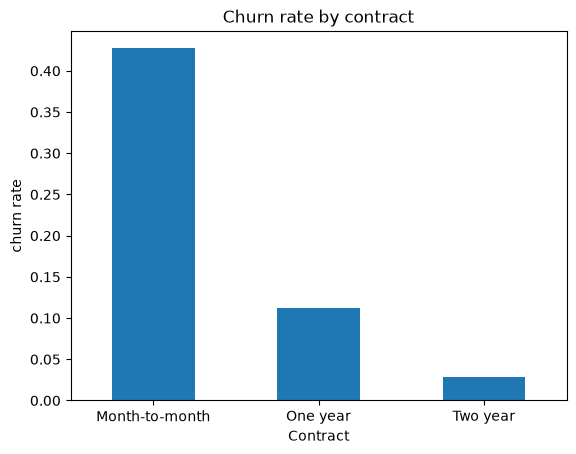

In [4]:
rate = lambda s: (s == "Yes").mean()
by_contract = df.groupby("Contract")["Churn"].apply(rate).sort_values(ascending=False)
print(by_contract.round(3))
by_contract.plot.bar(title="Churn rate by contract", ylabel="churn rate", rot=0)
plt.show()

**Finding 3:** _..._

## 4. Churn by tenure

tenure
0-6      0.529
7-12     0.359
13-24    0.287
25-48    0.204
49-72    0.095
Name: Churn, dtype: float64


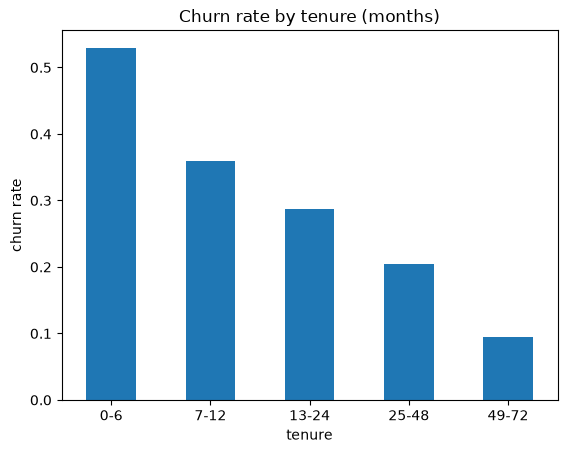

In [5]:
bands = pd.cut(df["tenure"], [-1, 6, 12, 24, 48, 72], labels=["0-6", "7-12", "13-24", "25-48", "49-72"])
by_tenure = df.groupby(bands, observed=True)["Churn"].apply(rate)
print(by_tenure.round(3))
by_tenure.plot.bar(title="Churn rate by tenure (months)", ylabel="churn rate", rot=0)
plt.show()

**Finding 4:** _..._

## 5. Churn by service and payment

In [6]:
for col in ["InternetService", "TechSupport", "PaymentMethod"]:
    print(df.groupby(col)["Churn"].apply(rate).sort_values(ascending=False).round(3))
    print()

InternetService
Fiber optic    0.419
DSL            0.190
No             0.074
Name: Churn, dtype: float64

TechSupport
No                     0.416
Yes                    0.152
No internet service    0.074
Name: Churn, dtype: float64

PaymentMethod
Electronic check             0.453
Mailed check                 0.191
Bank transfer (automatic)    0.167
Credit card (automatic)      0.152
Name: Churn, dtype: float64



**Finding 5:** _..._

## 6. Monthly charges

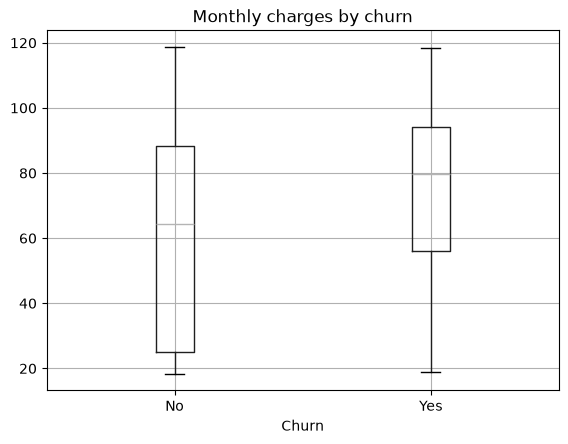

In [7]:
df.boxplot(column="MonthlyCharges", by="Churn")
plt.suptitle("")
plt.title("Monthly charges by churn")
plt.show()

**Finding 6:** _..._